In [1]:
from antares_devkit.models import BaseFilter
from antares_devkit.models import DevKitLocus
from antares_client import search
import numpy as np
import matplotlib.pyplot as plt
from astropy.time import Time
import pandas as pd
import math
from astropy.coordinates import Angle, SkyCoord
import astropy.units as u
import time
import warnings
import itertools
import pdb

fail_stats = {}

In [191]:
#extract data from lsst alert
def lsst_alert(alert):
    obs_date = float(alert.properties['lsst_diaSource_midpointMjdTai'])
    oid_mag = float(-2.5*np.log10(alert.properties['lsst_diaSource_scienceFlux']) + 31.4)
    temp_mag = float(-2.5*np.log10(alert.properties['lsst_diaSource_templateFlux']) + 31.4)
    diff_mag = float(temp_mag - oid_mag)
    
    bandpass = alert.properties['lsst_diaSource_band']
    band = 'lsst_' + str(bandpass)

    if alert.properties['lsst_diaSource_isNegative'] == True:
        pos_or_neg = -1
    else:
        pos_or_neg = 1
        
    return {band: [obs_date, oid_mag, temp_mag, diff_mag, pos_or_neg]}

def lsst_quality(alert):
    quality = True
    quality &= alert.properties['lsst_diaSource_reliability'] >= 0.6
    quality &= alert.properties['lsst_diaSource_psfFlux_flag'] == False
    quality &= alert.properties['lsst_diaSource_centroid_flag'] == False
    quality &= alert.properties['lsst_diaSource_shape_flag'] == False
    quality &= alert.properties['lsst_diaSource_isDipole'] == False
    quality &= alert.properties['lsst_diaSource_pixelFlags_saturated'] == False
    quality &= alert.properties['lsst_diaSource_pixelFlags_edge'] == False
    quality &= alert.properties['lsst_diaSource_pixelFlags_cr'] == False
    quality &= alert.properties['lsst_diaSource_pixelFlags_streak'] == False
    quality &= alert.properties['lsst_diaSource_scienceFlux'] >= 0
    quality &= alert.properties['lsst_diaSource_templateFlux'] >= 0

    if 'lsst_diaSource_ssObjectId' in alert.properties:
        quality &= alert.properties['lsst_diaSource_ssObjectId'] in (0, None, "0")
    return quality

#extract data from ztf alert
#uses formula from 260609 6/15 markdown cell
def ztf_alert(alert):
    bands = ['x', 'g', 'R', 'i']
    
    band_id = alert.properties['ztf_fid']
    obs_date = float(alert.properties['ant_mjd'])
    ant_mag = alert.properties['ant_mag']
    temp_mag = alert.properties['ztf_magnr']
    temp_mag_err = alert.properties['ztf_sigmagnr']
    diff_img_mag = alert.properties['ztf_magpsf']
    diff_img_mag_err = alert.properties['ztf_sigmapsf']
    
    if alert.properties['ztf_isdiffpos'] == 'f' or alert.properties['ztf_isdiffpos'] == 0:
        pos_or_neg = -1
        m =  (1 - 10.**(0.4*(temp_mag - diff_img_mag)))
    else:
        pos_or_neg = 1
        m = (10.**(0.4*(temp_mag - diff_img_mag)) + 1)

    if m <= 0.01:
        diff_mag = 10**(-10)
    else:
        diff_mag = -2.5* np.log10(m)
    oid_mag = diff_mag + temp_mag
    band = 'ztf_' + str(bands[band_id])
    return {band: [obs_date, oid_mag, temp_mag, diff_mag, pos_or_neg]}

def ztf_alert_err(alert):
    bands = ['x', 'g', 'R', 'i']
    
    band_id = alert.properties['ztf_fid']
    obs_date = float(alert.properties['ant_mjd'])
    ant_mag = alert.properties['ant_mag']
    temp_mag = alert.properties['ztf_magnr']
    temp_mag_err = alert.properties['ztf_sigmagnr']
    diff_img_mag = alert.properties['ztf_magpsf']
    diff_img_mag_err = alert.properties['ztf_sigmapsf']
    n = 10.**(0.4*(temp_mag - diff_img_mag))
    flag = 0
    
    if alert.properties['ztf_isdiffpos'] == 'f' or alert.properties['ztf_isdiffpos'] == 0:
        pos_or_neg = -1
        if 1-n <= 0.01:
            diff_mag = 10**(-10)
            oid_mag_err = np.sqrt( 2**2 *temp_mag_err**2 + diff_img_mag_err**2 )
            flag = 1
        else:
            diff_mag = -2.5* np.log10(1-n)
            oid_mag_err = np.sqrt( (1+n/(1-n))**2 * temp_mag_err**2 + (n/(1-n))**2 * diff_img_mag_err**2 )
    else:
        pos_or_neg = 1
        if 1+n <= 0.01:
            diff_mag = 10**(-10)
            oid_mag_err = np.sqrt( temp_mag_err**2 + (n/(1-n))**2 * diff_img_mag_err**2 )
            flag = 1
        else:
            diff_mag = -2.5* np.log10(1+n)
            oid_mag_err = np.sqrt( (1-n/(1+n))**2 * temp_mag_err**2 + (n/(1-n))**2 * diff_img_mag_err**2 )

    oid_mag = diff_mag + temp_mag
    band = 'ztf_' + str(bands[band_id])
    return {band: [obs_date, oid_mag, oid_mag_err, temp_mag, diff_mag, pos_or_neg, flag]}


#checks ztf alert for good quality
def ztf_quality(alert):
    quality = True
    quality &= alert.properties['ztf_rb'] >= 0.65
    quality &= alert.properties['ztf_nbad'] == 0
    quality &= alert.properties['ztf_fwhm'] <= 5
    quality &= alert.properties['ztf_elong'] <= 1.2
    quality &= abs(alert.properties['ztf_magdiff']) <= 0.1

    return quality

#unpacks all alerts (that pass a quality test)
def oid_get_info(alerts, latest_mjd):
    oid = {'lsst_g': 0, 'lsst_r': 0, 'lsst_i': 0, 'lsst_z': 0, 'lsst_u': 0, 'lsst_y': 0, 
               'ztf_g': 0, 'ztf_R': 0, 'ztf_i': 0}

    #snr check
    if alerts[-1].properties['ant_survey'] == 4:
        if alerts[-1].properties['lsst_diaSource_snr'] < 8:
            return 'snr too low'
        elif lsst_quality(alerts[-1]) == False:
            return 'lsst alert quality fail'
        else:  # check if bright
            trig_alert = lsst_alert(alerts[-1])
            band = [*trig_alert][0]
            if trig_alert[band][1] > 21:
                return 'triggered alert too dim'
    elif alerts[-1].properties['ant_survey'] == 1:
        if (1.0857/alerts[-1].properties['ztf_sigmapsf']) < 8:
            return 'snr too low'

    for alert in alerts:
        #check mjd
        if alert.properties['ant_mjd'] < (math.floor(latest_mjd) - 30):
            continue

        # quality check
        if alert.properties['ant_survey'] == 4:
            lsst_pass = lsst_quality(alert)
            if lsst_pass == True:
                comp = lsst_alert(alert)
            else:
                continue
        elif alert.properties['ant_survey'] == 1:
            ztf_pass = ztf_quality(alert)
            if ztf_pass == True:
                comp = ztf_alert(alert)
            else:
                continue
        else:
            continue
            
        band = [*comp][0]
        #put quality data together organized by band
        if isinstance(oid[band], pd.DataFrame) == 0:
            oid_df = pd.DataFrame([comp[band]], columns = ['mjd', 'oid_mag', 'template_mag', 'diff_mag', 'pos/neg'])
            oid[band] = oid_df
            continue
        else:
            data_df = pd.DataFrame([comp[band]], columns = ['mjd', 'oid_mag', 'template_mag', 'diff_mag', 'pos/neg'])
            current_data = oid[band]
            oid[band] = pd.concat([current_data, data_df]).drop_duplicates().reset_index(drop=True)

    #checking if any data passed
    fail = 0
    for band in oid:
        if isinstance(oid[band], pd.DataFrame) == False:
            fail += 1
    if fail == 9:
        return 'no recent data'
    else:
        return oid

def var_params(oid, make_targets = False):
    vp = {'lsst_g': 0, 'lsst_r': 0, 'lsst_i': 0, 'lsst_z': 0, 'lsst_u': 0, 'lsst_y': 0, 
               'ztf_g': 0, 'ztf_R': 0, 'ztf_i': 0}
    data_lim = 0
    for band in oid:
        if band == 'locus':
            continue
        if isinstance(oid[band], pd.DataFrame) == 0:
            data_lim += 1
            continue
        if len(oid[band]) < 3:
            data_lim += 1
            vp[band] = {'diff_mag':0, 'var':0, 'hyper_v':0, 'data':oid[band]}
        
        max_mjd_i = oid[band].mjd.idxmax()
        diff_mag = float(oid[band]['diff_mag'][max_mjd_i])
        var = np.var(oid[band]['oid_mag'])
        # hv = float(np.sqrt(diff_mag ** 2 + (coeff * var) ** 2))
        # vp[band] = {'diff_mag':diff_mag, 'var':var, 'hyper_v':hv, 'data':oid[band]}
        vp[band] = {'diff_mag':diff_mag, 'var':var, 'data':oid[band]}

    # if make_targets == True:
        
    if data_lim == 9:
        return 0
    else: 
        return vp

def catalog_check(locus):
    flags = {'known_star': False, 'known_agn': False, 'known_galaxy': False, 'gaia_likely_star': False, 
                            'gaia_astro_star': False, 'ps1_pointlike': False}
    for cat in locus.catalog_objects:
        if cat == 'asassn_variable_catalog' or cat == 'asassn_variable_Catalog_v2_20190802' or cat == 'sdss_stars':
            flags['known_star'] = True
        if cat == 'veron_agn_qso' or cat == 'milliquas':
            flags['known_agn'] = True
        if cat == '2mass_xsc' or cat == 'nyu_valueadded_gals' or cat == 'sdss_gals' or cat == 'RC3':
            flags['known_galaxy'] = True
        if cat == 'gaia_dr3_gaia_source':
            if isinstance(locus.catalog_objects[cat][0]['classprob_dsc_combmod_star'], float) == 1 and locus.catalog_objects[cat][0]['classprob_dsc_combmod_star'] > 0.5:
                flags['gaia_likely_star'] = True
            if isinstance(locus.catalog_objects[cat][0]['parallax'], float) == 1:
                gdr3_check1 = (locus.catalog_objects[cat][0]['parallax'] + 0.017)/locus.catalog_objects[cat][0]['parallax_error']
                alpha = locus.catalog_objects[cat][0]['pmra']/locus.catalog_objects[cat][0]['pmra_error']
                beta = locus.catalog_objects[cat][0]['pmdec']/locus.catalog_objects[cat][0]['pmdec_error']
                gamma = locus.catalog_objects[cat][0]['pmra_pmdec_corr']
                gdr3_check2 = np.sqrt((alpha**2 + beta**2 -2*alpha*beta*gamma)/(1 - gamma**2))
                if gdr3_check1 > 5 or gdr3_check2 > 5:
                    flags['gaia_astro_star'] = True
        alert_temp = locus.alerts[-1].properties
        if alert_temp['ant_survey'] == 1 and ((alert_temp['ztf_sgscore1'] > 0.5 and alert_temp['ztf_distpsnr1'] < 1) or (alert_temp['ztf_sgscore2'] > 0.5 and alert_temp['ztf_distpsnr2'] < 1) or (alert_temp['ztf_sgscore3'] > 0.5 and alert_temp['ztf_distpsnr3'] < 1)):
            flags['ps1_pointlike'] = True
    return flags

def query_by_chunk(mjd_start, mjd_end, ra_min, ra_max, dec_min, dec_max,
                   faint_lim=21, min_ndet=3, max_results=10000,
                   retries=3, wait=15):
    # set the query to fetch loci with alerts matching search criteria
    query = {
        "query": {
            "bool": {
                "filter": [
                    { "range": { "properties.newest_alert_observation_time": { "gte": mjd_start, "lte": mjd_end} } },
                    { "range": { "properties.brightest_alert_magnitude": {"lte": faint_lim} } },
                    { "range": { "ra": { "gte": ra_min, "lte": ra_max} } },
                    { "range": { "dec": { "gte": dec_min, "lte": dec_max} } }
                      ]
            }
        }
    }

    # sometimes the ANTARES server times out so try a few times
    # before giving up and returning an empty list (to avoid crashing the entire query)
    for attempt in range(retries):
        try:
            loci = list(search.search(query))
            if len(loci) >= max_results:
                warnings.warn(
                    f'Chunk MJD {mjd_start:.1f}–{mjd_end:.1f} hit the {max_results}-result max.'
                    f'— Reduce QUERY_DT or this window is incomplete.',
                    stacklevel=2
                )
            return get_ids(loci)
        except Exception as e:
            if attempt < retries - 1:
                print(f'  Chunk {mjd_start}–{mjd_end} failed (attempt {attempt+1}/{retries}): {e}.')
                time.sleep(wait)
            else:
                # print(f'  Chunk {mjd_start}–{mjd_end} giving up after {retries} attempts.')
                return []

def get_ids(loci):
    # print(loci)
    loci_ids = []
    for locus in loci:
        loci_ids.append(locus.locus_id)
    return loci_ids


def get_target_info(locus, oid):
    
    target = pd.DataFrame(columns = ['too_id','fiber_type','catalogid','sdss_id','gaia_dr3_source_id',
                                     'twomass_pts_key','sky_brightness_mode','ra','dec','pmra','pmdec',
                                     'epoch','parallax','lambda_eff','u_mag','g_mag','r_mag','i_mag','z_mag',
                                     'optical_prov','gaia_bp_mag','gaia_rp_mag','gaia_g_mag','h_mag',
                                     'delta_ra','delta_dec','can_offset','inertial','n_exposures','priority',
                                     'active','expiration_date','observed'])
    target.loc[0,'fiber_type'] = 'BOSS'
    for cat in locus.catalog_objects:
        if cat == 'sdss_gals':
            target.loc[0,'sdss_id'] = locus.catalog_objects[cat][0]['Objid']
        elif cat == 'sdss_stars':
            target.loc[0,'sdss_id'] = locus.catalog_objects[cat][0]['Objid']
        elif cat == 'gaia_dr3_gaia_source':
            target.loc[0,'gaia_dr3_source_id'] = locus.catalog_objects[cat][0]['Source Id']
        elif cat == '2mass_xsc':
            target.loc[0,'twomass_pts_key']= locus.catalog_objects[cat][0]['Id']

    target.loc[0,'sky_brightness_mode'] = 'dark'
    target.loc[0, 'ra'] = locus.ra
    target.loc[0,'dec'] = locus.dec

    
    passband = locus.alerts[-1].properties['ant_passband']
    if locus.alerts[-1].properties['ant_survey'] == 4: #lsst
        if passband == 'y':
            a  = 1
        else:
            target[passband+'_mag'].loc[0] = oid['lsst_'+passband]
    elif locus.alerts[-1].properties['ant_survey'] == 1:
        if passband == 'R':
            target.loc[0,'r_mag'] = oid['ztf_R']
        else:
            target.loc[0,passband+'_mag'] = oid['ztf_'+passband]

    target.loc[0, 'can_offset'] = True
    target.loc[0, 'n_exposures'] = 3
    target.loc[0, 'priority'] = 5
    target.loc[0, 'active'] = True
    target.loc[0, 'observed'] = False
    
    return target


def lightcurve(alerts):
    lc = {'lsst_g': 0, 'lsst_r': 0, 'lsst_i': 0, 'lsst_z': 0, 'lsst_u': 0, 'lsst_y': 0, 
         'ztf_g': 0, 'ztf_R': 0, 'ztf_i': 0}
    flag = 0
    for alert in alerts:
        # if alert.properties['ant_survey'] == 4:
        #     # lsst_pass = lsst_quality(alert)
        #     # if lsst_pass == True:
        #     comp = lsst_alert(alert)
            # else:
            #     continue
        if alert.properties['ant_survey'] == 1:
            # ztf_pass = ztf_quality(alert)
            # if ztf_pass == True:
            comp = ztf_alert_err(alert)
            # else:
            #     continue
        else:
            continue
        band = [*comp][0]
        flag += comp[band][-1]
        here = {'mjd': comp[band][0], 'mag':comp[band][1], 'mag_err':comp[band][2], 'temp_mag':comp[band][3]}
        # here = pd.DataFrame([[band], [comp[band][0]], [comp[band][1]]], columns = ['band', 'mjd', 'mag'])
        if isinstance(lc[band], pd.DataFrame) == 0:
            lc[band] = pd.DataFrame(data=here, index=[0])
        else:
            h = pd.DataFrame(data=here, index=[-1])
            lc[band] = pd.concat([lc[band], h]).reset_index(drop=True)
    return lc, flag

def lightcurve_quality(alerts):
    lc = {'lsst_g': 0, 'lsst_r': 0, 'lsst_i': 0, 'lsst_z': 0, 'lsst_u': 0, 'lsst_y': 0, 
         'ztf_g': 0, 'ztf_R': 0, 'ztf_i': 0}
    flag = 0
    for alert in alerts:
        if alert.properties['ant_survey'] == 4:
            lsst_pass = lsst_quality(alert)
            if lsst_pass == True:
                comp = lsst_alert(alert)
            else:
                continue
        elif alert.properties['ant_survey'] == 1:
            ztf_pass = ztf_quality(alert)
            if ztf_pass == True:
                comp = ztf_alert_err(alert)
            else:
                continue
        else:
            continue
        band = [*comp][0]
        flag += comp[band][-1]
        here = {'mjd': comp[band][0], 'mag':comp[band][1], 'mag_err':comp[band][2], 'temp_mag':comp[band][3]}
        # here = pd.DataFrame([[band], [comp[band][0]], [comp[band][1]]], columns = ['band', 'mjd', 'mag'])
        if isinstance(lc[band], pd.DataFrame) == 0:
            lc[band] = pd.DataFrame(data=here, index=[0])
        else:
            h = pd.DataFrame(data=here, index=[-1])
            lc[band] = pd.concat([lc[band], h]).reset_index(drop=True)
    return lc, flag
        

In [3]:
targets = pd.DataFrame(columns = ['too_id','fiber_type','catalogid','sdss_id','gaia_dr3_source_id',
                                 'twomass_pts_key','sky_brightness_mode','ra','dec','pmra','pmdec',
                                 'epoch','parallax','lambda_eff','u_mag','g_mag','r_mag','i_mag','z_mag',
                                 'optical_prov','gaia_bp_mag','gaia_rp_mag','gaia_g_mag','h_mag',
                                 'delta_ra','delta_dec','can_offset','inertial','n_exposures','priority',
                                 'active','expiration_date','observed'])
stats_now = {'snr':0, 'recency':0, 'trig_a_quality':0, 'faint':0, 'data_limitted':0,'variable':0,'checked':0}

oid_sample = {}

In [94]:

ra_s = np.arange(0, 360, 10)
dec_s = np.arange(-40, 40, 10)

t_now = Time.now().mjd
ids = [0]

for ra, dec in list(itertools.product(ra_s, dec_s)):
    RA_MIN = float(ra)
    RA_MAX = float(RA_MIN + 10)
    DEC_MIN = float(dec)
    DEC_MAX = float(DEC_MIN + 10)
    
    loci_ids = query_by_chunk(t_now-1, t_now, RA_MIN, RA_MAX, DEC_MIN, DEC_MAX)
    print(f'({RA_MIN} - {RA_MAX}, {DEC_MIN} - {DEC_MAX}) : {len(loci_ids)}')
    
    for l_id in loci_ids:
        locus = search.get_by_id(l_id)
        oid_dv = locus.to_devkit()
        oid_locus = DevKitLocus.model_validate(oid_dv)
        # id_here = pd.DataFrame({'ids':l_id})
        oid_here = oid_get_info(oid_locus.alerts, oid_locus.properties['newest_alert_observation_time'])
        ids += [l_id]
        if isinstance(oid_here, str):
            if oid_here == 'snr too low':
                stats_now['snr'] += 1
            elif oid_here == 'no recent data':
                stats_now['recency'] += 1
            elif oid_here == 'lsst alert quality fail':
                stats_now['trig_a_quality'] += 1
            elif oid_here == 'triggered alert too dim':
                stats_now['faint'] += 1
        else:
            for band in oid_here:
                if isinstance(oid_here[band], pd.DataFrame) == 0:
                    continue
                if len(oid_here[band]['diff_mag']) >= 3:
                    oid_sample[oid_dv['id']] = oid_here
                    # flags = catalog_check(oid_locus)
                    # oid_sample[oid_dv['id']]['flags'] = flags
                    
    stats_now['checked'] += len(loci_ids)
targets = targets.replace(np.nan, ' ', regex=True)
fail_stats[math.floor(t_now)] = stats_now

(0.0 - 10.0, -40.0 - -30.0) : 0
(0.0 - 10.0, -30.0 - -20.0) : 173
(0.0 - 10.0, -20.0 - -10.0) : 574
(0.0 - 10.0, -10.0 - 0.0) : 1272
(0.0 - 10.0, 0.0 - 10.0) : 1882
(0.0 - 10.0, 10.0 - 20.0) : 713
(0.0 - 10.0, 20.0 - 30.0) : 67
(0.0 - 10.0, 30.0 - 40.0) : 0
(10.0 - 20.0, -40.0 - -30.0) : 0
(10.0 - 20.0, -30.0 - -20.0) : 53
(10.0 - 20.0, -20.0 - -10.0) : 504
(10.0 - 20.0, -10.0 - 0.0) : 850
(10.0 - 20.0, 0.0 - 10.0) : 1849
(10.0 - 20.0, 10.0 - 20.0) : 1213
(10.0 - 20.0, 20.0 - 30.0) : 108
(10.0 - 20.0, 30.0 - 40.0) : 0
(20.0 - 30.0, -40.0 - -30.0) : 0
(20.0 - 30.0, -30.0 - -20.0) : 106
(20.0 - 30.0, -20.0 - -10.0) : 300
(20.0 - 30.0, -10.0 - 0.0) : 724
(20.0 - 30.0, 0.0 - 10.0) : 1386
(20.0 - 30.0, 10.0 - 20.0) : 1646
(20.0 - 30.0, 20.0 - 30.0) : 305
(20.0 - 30.0, 30.0 - 40.0) : 0
(30.0 - 40.0, -40.0 - -30.0) : 0
(30.0 - 40.0, -30.0 - -20.0) : 56
(30.0 - 40.0, -20.0 - -10.0) : 208
(30.0 - 40.0, -10.0 - 0.0) : 485
(30.0 - 40.0, 0.0 - 10.0) : 1386
(30.0 - 40.0, 10.0 - 20.0) : 1200
(30.0 -

ReadTimeout: HTTPSConnectionPool(host='api.antares.noirlab.edu', port=443): Read timed out. (read timeout=60)

In [ ]:
and oid_here[band]['diff_mag'][obs-1] >= 1

                    target = get_target_info(oid_locus, oid_here)
                    # print(f'target info: \n{target}\ntarget list: \n{targets}')
                    targets = pd.concat([targets, target]).drop_duplicates()

In [109]:
print(stats_now, len(targets))

{'snr': 12310, 'recency': 10760, 'trig_a_quality': 0, 'faint': 0, 'data_limitted': 0, 'variable': 0, 'checked': 41716} 147


In [106]:
stats_now
sr = (np.pi*30/180)*(np.pi*15/180)+(np.pi*5/180)*(np.pi*20/180) #total sr from this query
sr1 = 10*(np.pi*0.5/180)**2 #sdss fov min
sr2 = 10*(np.pi*0.75/180)**2 #sdss fov max
dens = len(targets)/sr
alert_dens = [dens, dens*sr1, dens*sr2]
alert_dens

[877.4046062758663, 0.6681818181818182, 1.5034090909090911]

In [115]:
len(ids)

26733

In [124]:
# len(targets)
dms
#161

,id,diff_mag
0,ANT2026o9xwbpkbjh7t,-2.704278
1,ANT2026rmg7e5tkh9dl,-5.320611
2,ANT2018g6coy,0.303329
3,ANT20262hhc0e2p2c3a,-4.941387
4,ANT2026mtpo9o25mkwh,-4.796898
...,...,...
561,ANT2026big4mh84y2um,-5.847572
562,ANT2026ogijvf4y0w2g,-3.862138
563,ANT202699qftzn9a4n5,-5.061532
564,ANT2026622f0nvqqcld,-3.295692


In [123]:
dms = pd.DataFrame(columns = ['id', 'diff_mag'])

for oid_id in ids[1:]:
    alerts = search.get_by_id(oid_id).alerts
    alert = alerts[-1]
    newest_mjd = alert.properties['ant_mjd']
    # print(1)
    if alert.properties['ant_survey'] == 4:
        lsst_pass = lsst_quality(alert)
        if lsst_pass == True:
            comp = lsst_alert(alert)
        else:
            continue
    elif alert.properties['ant_survey'] == 1:
        ztf_pass = ztf_quality(alert)
        if ztf_pass == True:
            comp = ztf_alert(alert)
        else:
            continue
    else:
        continue
        # print(2)
    band = [*comp][0]
    dm = comp[band][3]
    dms.loc[len(dms)] = [oid_id, dm]

ConnectionError: ('Connection aborted.', ConnectionResetError(54, 'Connection reset by peer'))

(array([ 66.,  14.,  15.,  40., 106., 161.,  87.,  53.,  15.,   9.]),
 array([0.14824134, 0.89655266, 1.64486397, 2.39317529, 3.14148661,
        3.88979793, 4.63810925, 5.38642056, 6.13473188, 6.8830432 ,
        7.63135452]),
 <BarContainer object of 10 artists>)

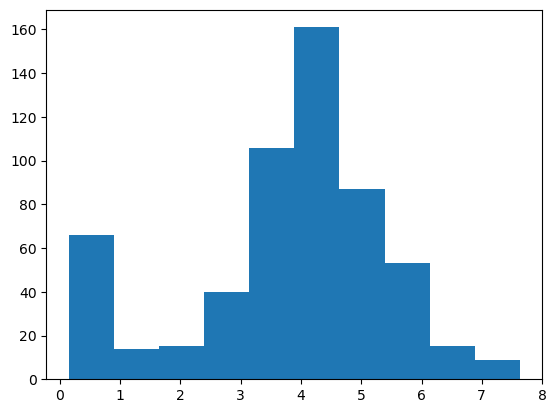

In [126]:
plt.hist(abs(dms['diff_mag']))

In [110]:

thresh = pd.DataFrame(columns = ['threshold', 'count', 'pass/good qual%', 'pass/total%', 'trig alerts/sr', 'trig alerts/f_low', 'trig alerts/f_high'])
ts = np.arange(0.1, 1.1,0.1)
for t in ts:
    sr1 = 10*(np.pi*0.5/180)**2
    sr2 = 10*(np.pi*0.75/180)**2
    count = sum(abs(v) > t for v in dms)
    density = count/(13*(np.pi**2)/18)
    thresh.loc[t*10-1] = [t, count, density, density*sr1, density*sr2]
    # print(f'note: these numbers come from using 75% of sky from observations on 09/05/26\nthreshold, % from good data, % from total query\n')
thresh  
# print(sr1*100/(13*(np.pi/18)**2), sr2*100/(13*(np.pi**2)/18))

ValueError: cannot set a row with mismatched columns

In [70]:
oid_sample['ANT2020arszo']

{'lsst_g': 0,
 'lsst_r': 0,
 'lsst_i': 0,
 'lsst_z': 0,
 'lsst_u': 0,
 'lsst_y': 0,
 'ztf_g':             mjd    oid_mag  template_mag  diff_mag  pos/neg
 0  61278.466516  17.449179     17.894001 -0.444822        1
 1  61294.327072  19.146843     17.894001  1.252842       -1
 2  61296.374398  17.545717     17.894001 -0.348284        1
 3  61298.401875  17.625257     17.894001 -0.268744        1
 4  61301.317651  17.599368     17.894001 -0.294633        1
 5  61302.333599  19.443545     17.894001  1.549544       -1
 6  61303.298681  17.409124     17.894001 -0.484877        1
 7  61305.400903  17.480397     17.894001 -0.413604        1,
 'ztf_R':             mjd    oid_mag  template_mag  diff_mag  pos/neg
 0  61295.381285  19.185293     17.830999  1.354294       -1
 1  61300.351609  17.571678     17.830999 -0.259322        1
 2  61301.363738  19.367099     17.830999  1.536100       -1
 3  61305.296285  17.302058     17.830999 -0.528941        1
 4  61306.297905  19.428955     17.830999  

In [188]:
oid_sample['ANT2018gxcyw']

{'lsst_g': 0,
 'lsst_r': 0,
 'lsst_i': 0,
 'lsst_z': 0,
 'lsst_u': 0,
 'lsst_y': 0,
 'ztf_g':              mjd    oid_mag  template_mag      diff_mag  pos/neg
 0   61282.378333  20.234151     18.316999  1.917151e+00       -1
 1   61284.355926  21.450837     18.316999  3.133838e+00       -1
 2   61286.357558  21.603695     18.801001  2.802695e+00       -1
 3   61286.358021  22.375455     18.316999  4.058456e+00       -1
 4   61287.356076  22.866757     18.801001  4.065756e+00       -1
 5   61287.356539  21.118460     18.316999  2.801461e+00       -1
 6   61288.354965  21.521214     18.801001  2.720214e+00       -1
 7   61288.355440  21.019773     18.316999  2.702774e+00       -1
 8   61293.331944  21.377310     18.316999  3.060311e+00       -1
 9   61296.355984  21.821878     18.801001  3.020878e+00       -1
 10  61296.356447  21.430505     18.316999  3.113506e+00       -1
 11  61297.313843  21.860407     18.316999  3.543408e+00       -1
 12  61298.277720  21.434311     18.316999  3.117

ANT2018gxcyw ztf_g               mjd        mag   mag_err   temp_mag
0    58369.327569  19.949069  0.290131  18.316999
1    58372.397326  18.223661  0.268042  18.801001
2    58372.398704  20.084029  0.325312  18.316999
3    58375.418357  20.334377  0.361121  18.801001
4    58375.419271  20.107365  0.368410  18.316999
..            ...        ...       ...        ...
365  61314.224664  18.316999  0.107501  18.316999
366  61315.314143  21.654026  1.845690  18.801001
367  61316.325347  22.184511  2.458237  18.316999
368  61317.334583  21.718078  1.948893  18.316999
369  61318.271366  21.459365  1.261606  18.316999

[370 rows x 4 columns]
ANT2018gxcyw ztf_R               mjd        mag   mag_err   temp_mag
0    58372.355463  19.257220  0.128031  18.264000
1    58372.356829  19.284292  0.143010  18.494999
2    58375.352847  19.502033  0.170497  18.264000
3    58378.381447  19.468351  0.150111  18.264000
4    58378.381898  19.378945  0.153153  18.495001
..            ...        ...       ...

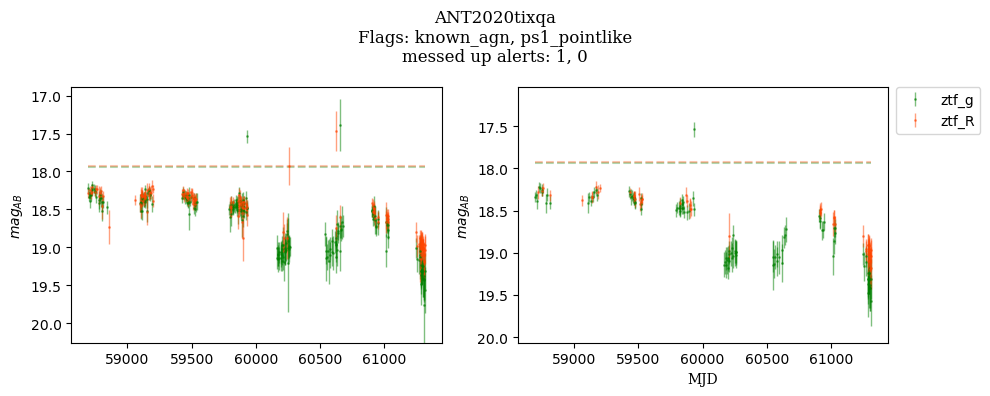

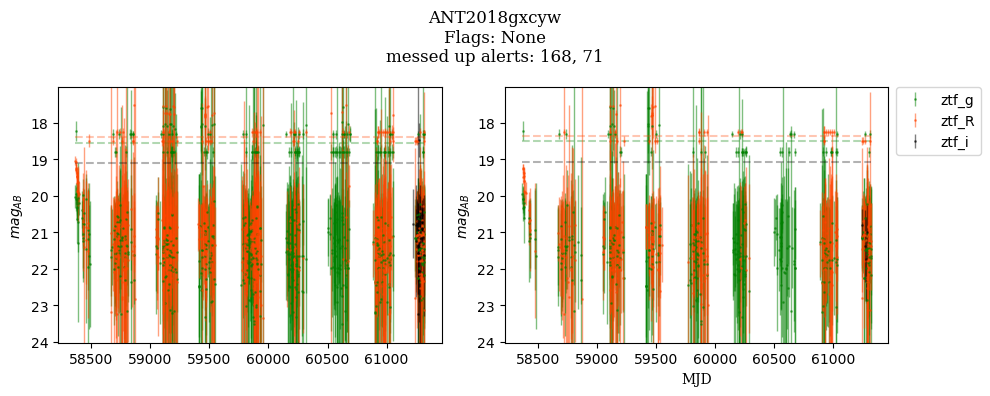

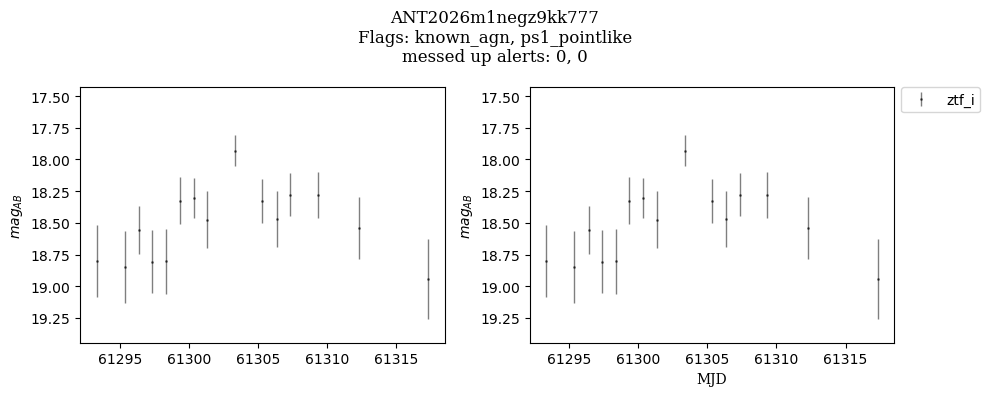

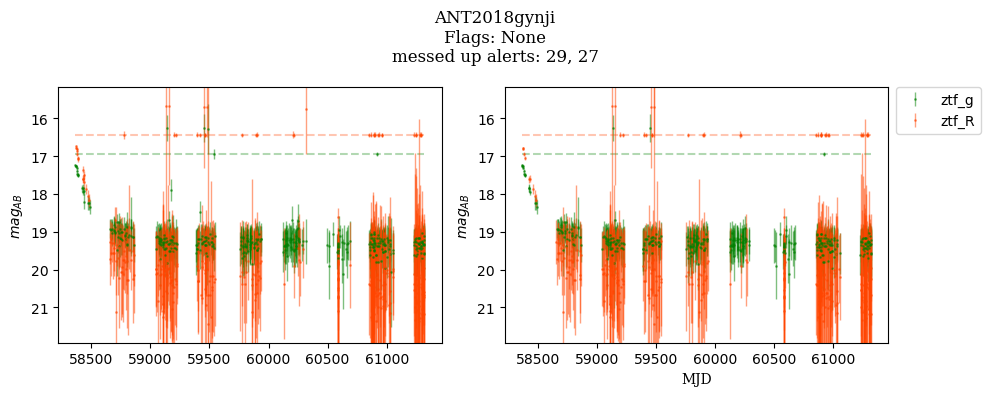

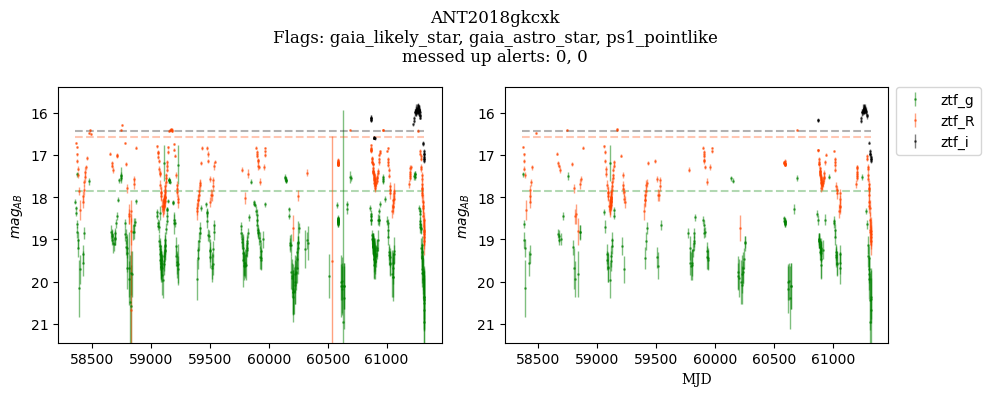

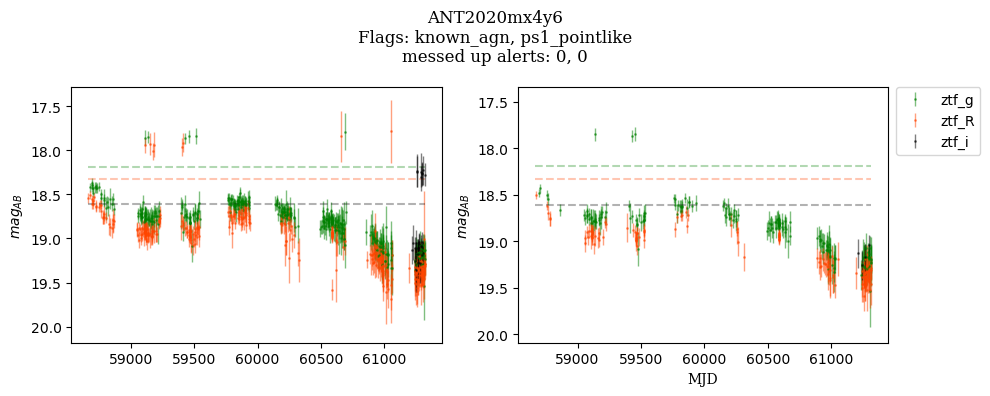

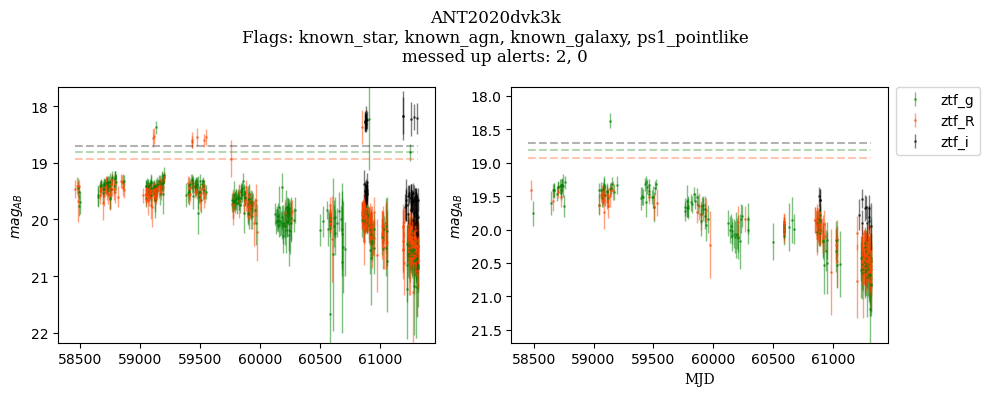

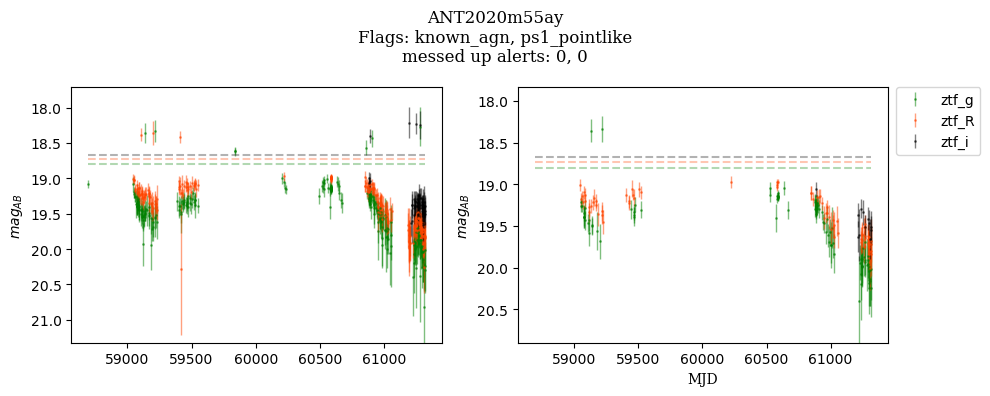

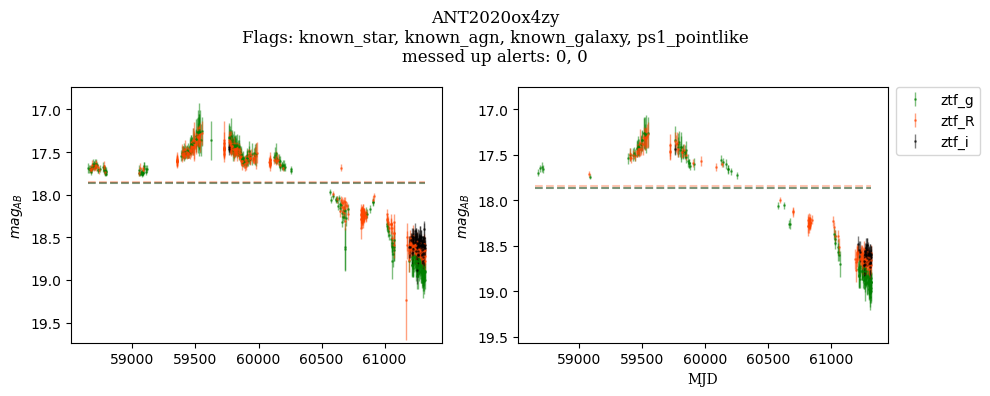

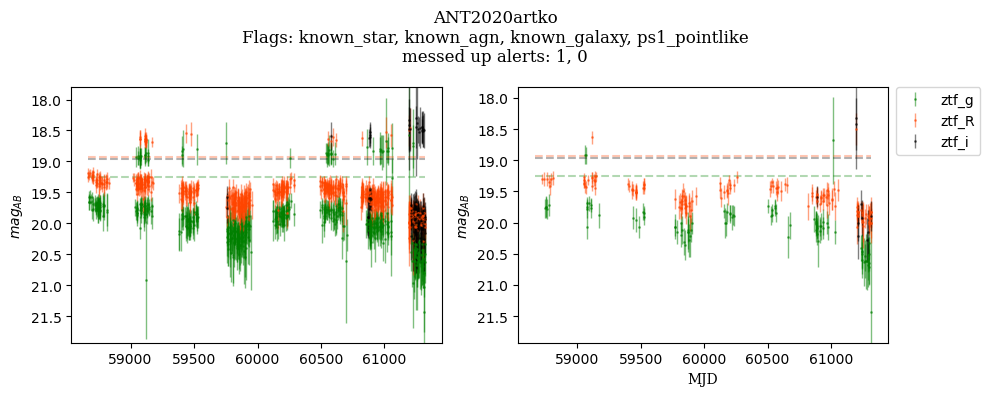

In [194]:
colors = {'ztf_g': 'green', 'ztf_R': 'orangered', 'ztf_i': 'black'}
for oid_id in list(oid_sample.keys())[:10]:
    fig, ax = plt.subplots(1,2, figsize=(10,4), sharey=False)

    locus = search.get_by_id(oid_id)
    lc, flag_n = lightcurve(locus.alerts)
    lc_q, flag_nq = lightcurve_quality(locus.alerts)
    title = oid_id
    max_lc = []
    min_lc = []
    max_lc_q = []
    min_lc_q = []
    flags_str = 'Flags: '
    
    for band in lc:
        if isinstance(lc[band], pd.DataFrame) == 0:
            continue
        max_lc += [max(lc[band]['mag'])]
        min_lc += [min(lc[band]['mag'])]
        ax[0].errorbar(lc[band]['mjd'], lc[band]['mag'], yerr=lc[band]['mag_err'], fmt='.', ms=2, lw=1, c = colors[band], ecolor = colors[band], label=band, alpha = 0.5)
        ax[0].hlines(y=np.average(lc[band]['temp_mag']), xmin = locus.properties['oldest_alert_observation_time'], xmax= locus.properties['newest_alert_observation_time'], 
                      colors = colors[band], alpha = 0.3, ls = '--')
        
    for band in lc_q:
        if isinstance(lc_q[band], pd.DataFrame) == 0:
            continue        
        max_lc_q += [max(lc_q[band]['mag'])]
        min_lc_q += [min(lc_q[band]['mag'])]
        ax[1].errorbar(lc_q[band]['mjd'], lc_q[band]['mag'], yerr=lc_q[band]['mag_err'], fmt='.', ms=2, lw=1, c = colors[band], ecolor = colors[band], label=band, alpha=0.5)
        ax[1].hlines(y=np.average(lc_q[band]['temp_mag']), xmin = locus.properties['oldest_alert_observation_time'], xmax= locus.properties['newest_alert_observation_time'], 
                      colors = colors[band], alpha = 0.3, ls = '--')

        if max(max_lc_q) > 20.5:
            print(oid_id, band, lc_q[band])
    flags = catalog_check(locus)
    for flag in flags:
        if flags[flag] == True and len(flags_str) == 7:
            flags_str += flag
        elif flags[flag] == True:
            flags_str += ', ' + flag
            
    ax[0].set(ylim=(min(min_lc)-0.5, max(max_lc)+0.5))
    ax[1].set(ylim=(min(min_lc_q)-0.5, max(max_lc_q)+0.5))
    ax[0].yaxis.set_inverted(True)
    ax[1].yaxis.set_inverted(True)
    ax[1].legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0.)

    if len(flags_str) > 7:
        fig.suptitle(title + '\n' + flags_str + '\nmessed up alerts: ' + str(flag_n) + ', ' + str(flag_nq), fontname = 'serif')
    else:
        fig.suptitle(title + '\n' + flags_str + 'None\nmessed up alerts: ' + str(flag_n) + ', ' + str(flag_nq), fontname = 'serif')
    plt.xlabel('MJD', fontname = 'serif')
    ax[0].set_ylabel('$mag_{AB}$', fontname = 'serif')
    ax[1].set_ylabel('$mag_{AB}$', fontname = 'serif')
    plt.tight_layout()